In [2]:
# ==============================================================
# LOCAL PROJECT SETUP (added during VS Code migration)
# Portable replacement for Google Colab / Google Drive mounting.
# All research code below this block is unchanged.
# ==============================================================
import sys as _sys
from pathlib import Path as _Path

def _locate_project_root():
    start = _Path.cwd().resolve()
    for candidate in [start] + list(start.parents):
        if (candidate / "src" / "ecg_qpain" / "paths.py").is_file():
            return candidate
    return start

PROJECT_ROOT = _locate_project_root()
_src = str(PROJECT_ROOT / "src")
if _src not in _sys.path:
    _sys.path.insert(0, _src)

from ecg_qpain.paths import (
    ROOT, BASE_DIR, PROJECT_DIR, DRIVE_DIR, MYDRIVE, MOUNT_POINT, mount_path,
    DATA_DIR, RAW_DIR, PROCESSED_DIR, MODELS_DIR, REPORTS_DIR,
    MITDB_DIR, NSTDB_DIR, MITDB_EXTRACTED, NSTDB_EXTRACTED,
    B2_DIR, B3_DIR, B4_DIR,
)
print("Local project root:", PROJECT_ROOT)
# ==============================================================

# (pip install moved to requirements.txt; run: pip install -r requirements.txt)

In [3]:
from pathlib import Path

ROOT = Path(str(PROJECT_ROOT))

folders = [
    'notebooks',
    'data/raw/mitdb',
    'data/raw/nstdb',
    'data/interim',
    'data/processed',
    'splits',
    'src',
    'configs',
    'checkpoints',
    'logs',
    'results',
    'figures',
    'reports',
    'paper'
]

for folder in folders:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)

print("All project folders created successfully!")
print("Project location:", ROOT)

All project folders created successfully!
Project location: /content/drive/MyDrive/ECG_QPAIN_2027


In [4]:
import sys
import torch
import wfdb
import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib

print("Python Version:", sys.version)
print("PyTorch Version:", torch.__version__)
print("WFDB Version:", wfdb.__version__)
print("NumPy Version:", np.__version__)
print("Pandas Version:", pd.__version__)
print("SciPy Version:", scipy.__version__)
print("Scikit-learn Version:", sklearn.__version__)

print("\nGPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

Python Version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch Version: 2.14.1+cu130
WFDB Version: 4.3.1
NumPy Version: 2.4.6
Pandas Version: 2.2.3
SciPy Version: 1.16.3
Scikit-learn Version: 1.6.1

GPU Available: True
GPU Name: Tesla T4


In [5]:
import wfdb
import numpy as np
import matplotlib.pyplot as plt

# Read first 10 seconds of ECG record 100
record = wfdb.rdrecord(
    '100',
    pn_dir='mitdb',
    sampfrom=0,
    sampto=3600
)

# Read ECG annotations
ann = wfdb.rdann(
    '100',
    'atr',
    pn_dir='mitdb',
    sampfrom=0,
    sampto=3600
)

print("ECG Record Loaded Successfully!")

print("Sampling Frequency:", record.fs)
print("ECG Leads:", record.sig_name)
print("Signal Shape:", record.p_signal.shape)
print("Total Annotations:", len(ann.sample))

ECG Record Loaded Successfully!
Sampling Frequency: 360
ECG Leads: ['MLII', 'V5']
Signal Shape: (3600, 2)
Total Annotations: 14


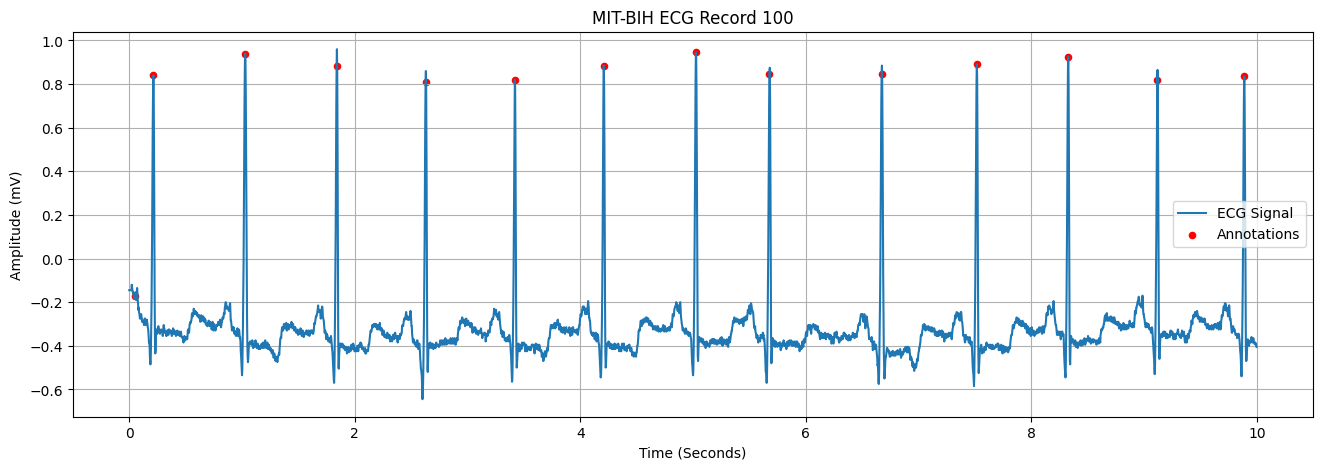

In [6]:
# Select first ECG lead for smoke testing
signal = record.p_signal[:, 0]

# Time axis
time = np.arange(len(signal)) / record.fs

# Plot ECG
plt.figure(figsize=(16, 5))

plt.plot(time, signal, label='ECG Signal')

# Plot annotations
annotation_time = ann.sample / record.fs

plt.scatter(
    annotation_time,
    signal[ann.sample],
    color='red',
    s=20,
    label='Annotations'
)

plt.title('MIT-BIH ECG Record 100')
plt.xlabel('Time (Seconds)')
plt.ylabel('Amplitude (mV)')

plt.legend()
plt.grid()

plt.savefig(
    ROOT / 'figures/record100_smoke_test.png',
    dpi=300
)

plt.show()

In [7]:
# Validation checks

assert record.fs == 360, "Incorrect sampling frequency!"

assert len(ann.sample) > 0, "No annotations found!"

assert np.isfinite(record.p_signal).all(), "Invalid ECG values!"

assert record.p_signal.shape[0] == 3600, "Incorrect sample count!"

assert np.all(ann.sample >= 0), "Invalid annotation positions!"

assert np.all(ann.sample < len(signal)), "Annotation outside signal range!"

print("================================")
print("ALL VALIDATION TESTS PASSED!")
print("================================")

ALL VALIDATION TESTS PASSED!


In [8]:
import sys
import json
import torch
import wfdb
import numpy as np
import pandas as pd
import scipy
import sklearn

environment = {
    "python": sys.version,
    "pytorch": torch.__version__,
    "wfdb": wfdb.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "sklearn": sklearn.__version__,
    "sampling_frequency": record.fs,
    "record": "100",
    "signal_shape": list(record.p_signal.shape),
    "annotations": len(ann.sample),
    "gpu_available": torch.cuda.is_available()
}

output_path = ROOT / 'reports/environment.json'

with open(output_path, 'w') as f:
    json.dump(environment, f, indent=4)

print("Environment information saved!")
print(output_path)




Environment information saved!
/content/drive/MyDrive/ECG_QPAIN_2027/reports/environment.json


In [9]:
print("PROJECT FILES")

for path in ROOT.rglob('*'):
    if path.is_file():
        print(path.relative_to(ROOT))

PROJECT FILES
reports/environment.json
figures/record100_smoke_test.png
